In [1]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

spark = SparkSession.builder \
    .appName("UrbanHub - Partie 4") \
    .config("spark.driver.memory", "4g") \
    .config("spark.jars.packages", "org.apache.hadoop:hadoop-aws:3.3.4,com.amazonaws:aws-java-sdk-bundle:1.12.262") \
    .config("spark.hadoop.fs.s3a.endpoint", "http://minio:9000") \
    .config("spark.hadoop.fs.s3a.access.key", "minioadmin") \
    .config("spark.hadoop.fs.s3a.secret.key", "minioadmin123") \
    .config("spark.hadoop.fs.s3a.path.style.access", "true") \
    .config("spark.hadoop.fs.s3a.impl", "org.apache.hadoop.fs.s3a.S3AFileSystem") \
    .config("spark.hadoop.fs.s3a.connection.ssl.enabled", "false") \
    .config("spark.sql.session.timeZone", "UTC") \
    .getOrCreate()

print("Spark pret :", spark.version)

Spark pret : 3.5.1


In [2]:
# 1. Meteo : une ligne par ville et par heure
meteo = spark.read.parquet("s3a://urbanhub/gold/meteo_horaire_ville/")

# 2. Pollution : historique (90 jours) + flux IoT en direct (depuis le 21/10), empiles
hist = (spark.read.parquet("s3a://silver/pollution/historique/")
    .select("ville", "sensor_id", "pollutant", F.col("value").cast("double"), "timestamp"))
flux = (spark.read.option("recursiveFileLookup", "true").json("s3a://bronze/pollution/flux/")
    .select("ville", "sensor_id", "pollutant", F.col("value").cast("double"),
            F.to_timestamp("timestamp").alias("timestamp")))
mesures = (hist.unionByName(flux)
    .filter(F.col("value").between(0, 20000))
    .dropDuplicates(["sensor_id", "timestamp"]))     # une mesure peut etre dans les deux

pollution = (mesures
    .withColumnRenamed("ville", "city")
    .withColumn("timestamp", F.date_trunc("hour", "timestamp"))
    .groupBy("city", "timestamp")
    .pivot("pollutant", ["no2", "o3", "pm10", "pm25", "co"])
    .agg(F.avg("value")))

# 3. Velos : mouvements par heure
velos = (spark.read.parquet("s3a://urbanhub/gold/velos_horaire_ville/")
    .select("city", "timestamp", "mouvements_par_heure", "remplissage_moy"))

# 4. JOINTURE : meme ville + meme heure
croise = (meteo.join(pollution, ["city", "timestamp"], "inner")
               .join(velos, ["city", "timestamp"], "left"))

print("Heures meteo        :", meteo.count())
print("Heures pollution    :", pollution.count())
print("Heures croisees     :", croise.count())
print("... dont avec velos :", croise.filter(F.col("mouvements_par_heure").isNotNull()).count())
croise.select("city", "timestamp", "hour_local", "temperature", "wind_speed",
              "precipitation", "no2", "pm25", "mouvements_par_heure").orderBy(F.desc("timestamp")).show(5)

Heures meteo        : 11095
Heures pollution    : 10719
Heures croisees     : 10710
... dont avec velos : 30
+--------+-------------------+----------+-----------+------------------+-------------+----+------------------+--------------------+
|    city|          timestamp|hour_local|temperature|        wind_speed|precipitation| no2|              pm25|mouvements_par_heure|
+--------+-------------------+----------+-----------+------------------+-------------+----+------------------+--------------------+
|   Paris|2026-10-22 10:00:00|        12|       12.4|3.9699999999999998|          0.0|NULL|0.8888888888888888|                NULL|
|Toulouse|2026-10-22 10:00:00|        12|       12.7|              0.86|          0.0|NULL|               0.2|                NULL|
|    Lyon|2026-10-22 10:00:00|        12|       11.4|              0.63|          0.0|NULL|1.4749999999999999|                NULL|
|Bordeaux|2026-10-22 10:00:00|        12|       15.9|              3.64|          0.0|NULL|        

Q1 - Correlations meteo / pollution :
                no2    o3  pm25  pm10
temperature    0.07  0.72  0.04  0.26
wind_speed    -0.35  0.41 -0.18 -0.11
humidity      -0.10 -0.65  0.20 -0.21
precipitation -0.01 -0.01 -0.00 -0.06
pressure       0.10 -0.09 -0.01  0.08


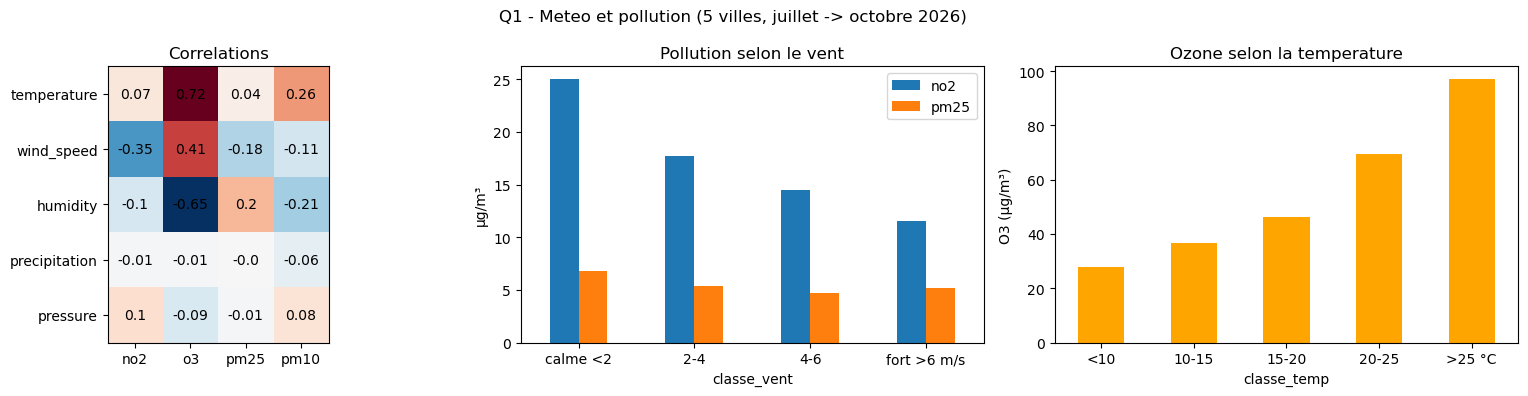


Heures avec velos : 24 (resultats provisoires, a relancer ce week-end)
Q2 - Correlations meteo / velos :
temperature     -0.16
wind_speed       0.19
precipitation    0.13
humidity        -0.10
Name: mouvements_par_heure, dtype: float64

Q3 - Utilisation (100 = moyenne de la ville) :
favorable
defavorable     93.0
favorable      108.0
Name: indice, dtype: float64


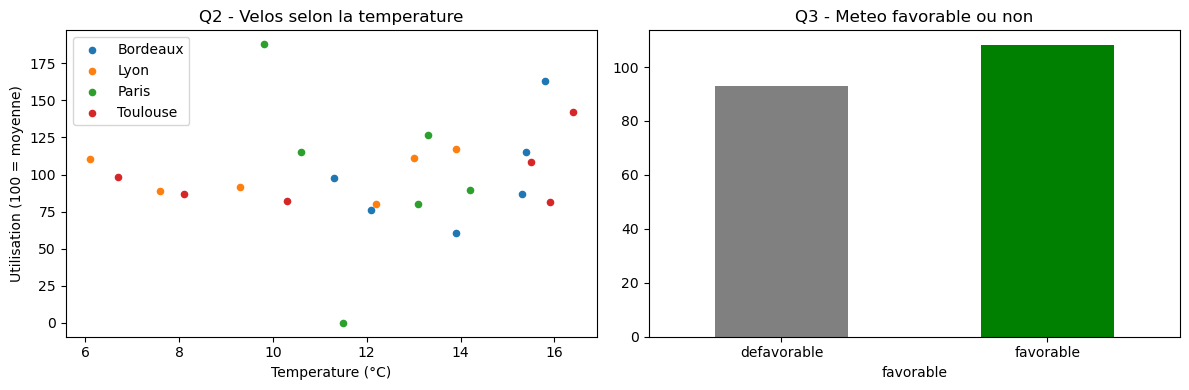


Q4 - Jours d'interaction forte, par ville et par type :
type       calme + NO2 eleve (air bloque)  chaleur + ozone eleve  \
city                                                               
Bordeaux                                2                      0   
Lyon                                   10                      0   
Marseille                              14                      2   
Paris                                  16                      0   
Toulouse                                9                      0   

type       particules fines elevees  
city                                 
Bordeaux                          8  
Lyon                              6  
Marseille                         8  
Paris                             3  
Toulouse                          5  


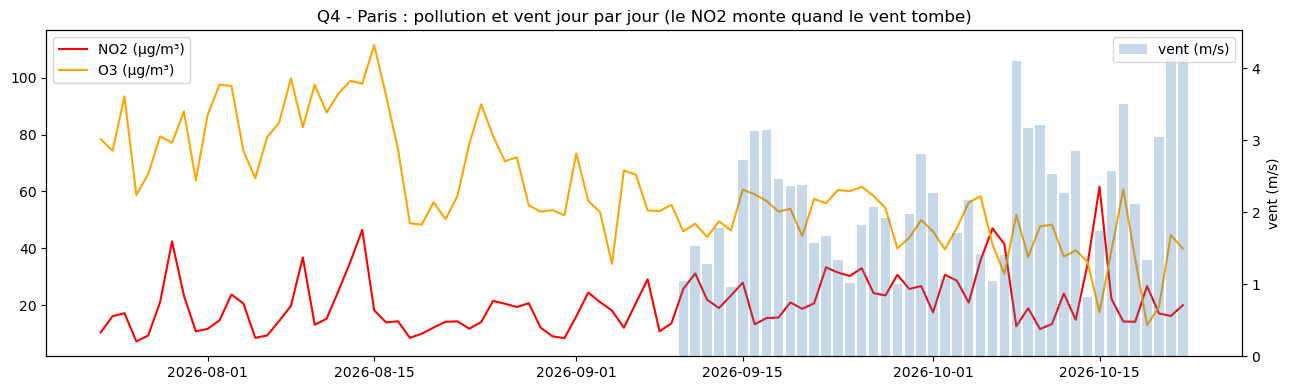


Gold : croisement_horaire_ville et croisement_journalier_ville enregistres.


In [3]:
import os
import pandas as pd
import matplotlib.pyplot as plt
FIG = "/home/jovyan/work/data/figures"; os.makedirs(FIG, exist_ok=True)

# Table croisee -> Gold (pour toute l'equipe) puis pandas pour les analyses
croise.write.mode("overwrite").parquet("s3a://urbanhub/gold/croisement_horaire_ville/")
df = croise.toPandas()
df["date_local"] = pd.to_datetime(df["date_local"])

# ================= Q1 : meteo <-> pollution
polluants, meteo_vars = ["no2", "o3", "pm25", "pm10"], ["temperature", "wind_speed", "humidity", "precipitation", "pressure"]
corr = df[meteo_vars + polluants].corr().loc[meteo_vars, polluants].round(2)
print("Q1 - Correlations meteo / pollution :"); print(corr)

df["classe_vent"] = pd.cut(df["wind_speed"], [-1, 2, 4, 6, 100], labels=["calme <2", "2-4", "4-6", "fort >6 m/s"])
vent = df.groupby("classe_vent", observed=True)[["no2", "pm25"]].mean()
df["classe_temp"] = pd.cut(df["temperature"], [-50, 10, 15, 20, 25, 60], labels=["<10", "10-15", "15-20", "20-25", ">25 °C"])
chaleur = df.groupby("classe_temp", observed=True)["o3"].mean()
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].imshow(corr, cmap="RdBu_r", vmin=-0.6, vmax=0.6)
ax[0].set_xticks(range(len(polluants)), polluants); ax[0].set_yticks(range(len(meteo_vars)), meteo_vars)
for i in range(len(meteo_vars)):
    for j in range(len(polluants)): ax[0].text(j, i, corr.iloc[i, j], ha="center", va="center")
ax[0].set_title("Correlations")
vent.plot(kind="bar", ax=ax[1], rot=0); ax[1].set_title("Pollution selon le vent"); ax[1].set_ylabel("µg/m³")
chaleur.plot(kind="bar", ax=ax[2], rot=0, color="orange"); ax[2].set_title("Ozone selon la temperature"); ax[2].set_ylabel("O3 (µg/m³)")
plt.suptitle("Q1 - Meteo et pollution (5 villes, juillet -> octobre 2026)"); plt.tight_layout()
plt.savefig(f"{FIG}/p4_q1_meteo_pollution.png", dpi=120); plt.show()

# ================= Q2 et Q3 : meteo <-> velos (seulement les heures ou on a des velos)
v = df[df["mouvements_par_heure"].notna() & (df["city"] != "Marseille")].copy()
print(f"\nHeures avec velos : {len(v)} (resultats provisoires, a relancer ce week-end)")
if len(v) >= 10:
    print("Q2 - Correlations meteo / velos :")
    print(v[["temperature", "wind_speed", "precipitation", "humidity", "mouvements_par_heure"]].corr()["mouvements_par_heure"].round(2).drop("mouvements_par_heure"))
    v["pluie"] = v["precipitation"] > 0.1
    v["favorable"] = v["temperature"].between(12, 28) & ~v["pluie"] & (v["wind_speed"] < 6)
    # on compare chaque heure a la moyenne de SA ville (Paris a beaucoup plus de velos que Bordeaux)
    v["indice"] = v["mouvements_par_heure"] / v.groupby("city")["mouvements_par_heure"].transform("mean") * 100
    q3 = v.groupby("favorable")["indice"].mean().rename({True: "favorable", False: "defavorable"})
    print("\nQ3 - Utilisation (100 = moyenne de la ville) :"); print(q3.round(0))
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    for c, g in v.groupby("city"): ax[0].scatter(g["temperature"], g["indice"], label=c, s=20)
    ax[0].set_xlabel("Temperature (°C)"); ax[0].set_ylabel("Utilisation (100 = moyenne)"); ax[0].legend(); ax[0].set_title("Q2 - Velos selon la temperature")
    q3.plot(kind="bar", ax=ax[1], rot=0, color=["grey", "green"]); ax[1].set_title("Q3 - Meteo favorable ou non")
    plt.tight_layout(); plt.savefig(f"{FIG}/p4_q2_q3_meteo_velos.png", dpi=120); plt.show()

# ================= Q4 : jours ou meteo + pollution (+ velos) interagissent fortement
jour = df.groupby(["city", "date_local"]).agg(temp=("temperature", "mean"), vent=("wind_speed", "mean"),
          pluie=("precipitation", "sum"), no2=("no2", "mean"), o3=("o3", "mean"), pm25=("pm25", "mean"),
          velos=("mouvements_par_heure", "mean")).reset_index()
jour["type"] = None
jour.loc[(jour["vent"] < 2.5) & (jour["no2"] > 25), "type"] = "calme + NO2 eleve (air bloque)"
jour.loc[(jour["temp"] > 24) & (jour["o3"] > 90), "type"] = "chaleur + ozone eleve"
jour.loc[jour["pm25"] > 15, "type"] = jour.loc[jour["pm25"] > 15, "type"].fillna("particules fines elevees")
episodes = jour[jour["type"].notna()]
spark.createDataFrame(jour.assign(date_local=jour["date_local"].dt.date).astype({"type": str})) \
     .write.mode("overwrite").parquet("s3a://urbanhub/gold/croisement_journalier_ville/")
print("\nQ4 - Jours d'interaction forte, par ville et par type :")
print(episodes.groupby(["city", "type"]).size().unstack(fill_value=0))

fig, ax1 = plt.subplots(figsize=(13, 4))
p = jour[jour["city"] == "Paris"].sort_values("date_local")
ax1.plot(p["date_local"], p["no2"], color="red", label="NO2 (µg/m³)")
ax1.plot(p["date_local"], p["o3"], color="orange", label="O3 (µg/m³)")
ax2 = ax1.twinx(); ax2.bar(p["date_local"], p["vent"], color="steelblue", alpha=0.3, label="vent (m/s)")
ax1.set_title("Q4 - Paris : pollution et vent jour par jour (le NO2 monte quand le vent tombe)")
ax1.legend(loc="upper left"); ax2.legend(loc="upper right"); ax2.set_ylabel("vent (m/s)")
plt.tight_layout(); plt.savefig(f"{FIG}/p4_q4_paris_pollution_vent.png", dpi=120); plt.show()
print("\nGold : croisement_horaire_ville et croisement_journalier_ville enregistres.")